In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv("와이파이_생활인구_통합.csv")

In [3]:
# 1. 데이터 준비 및 스케일링 (기존과 동일)
X = df[["고령인구비율"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# 2. 교수님 피드백 반영: k값을 3에서 5로 증가 (더 세밀한 분류)
k = 5

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# '고령인구_군집' 컬럼에 군집 분석 결과(0~4) 저장
df['고령인구_군집'] = kmeans.fit_predict(X_scaled)

In [ ]:
# 3. 군집별 평균 고령인구비율을 계산하고 오름차순 정렬
# (고령인구비율이 낮을수록 '양호', 높을수록 '취약'으로 라벨링)
cluster_means = df.groupby('고령인구_군집')['고령인구비율'].mean().sort_values()

# 4. 정렬된 순서대로 군집명(Label) 매핑 딕셔너리 생성
# K=5 기준: 1단계(매우 양호) ~ 5단계(매우 취약)
labels = [
    '저령(매우 양호)',
    '중저령(양호)',
    '중령(보통)',
    '중고령(취약)',
    '초고령(매우 취약)'
]
cluster_mapping = {}

for idx, (cluster_num, _) in enumerate(cluster_means.items()):
    cluster_mapping[cluster_num] = labels[idx]

# 5. '군집명' 컬럼 추가
df['군집명'] = df['고령인구_군집'].map(cluster_mapping)

In [ ]:
# 6. 결과 확인
print("--- 데이터 상위 10개 확인 ---")
print(df[['행정동코드', '고령인구비율', '고령인구_군집', '군집명']].head(10))

print("\n--- 각 군집별 데이터 개수 및 평균 고령인구비율 ---")
# 군집이 제대로 나뉘었는지, 평균 비율이 순서대로 정렬되었는지 확인
summary = df.groupby('군집명')['고령인구비율'].agg(['count', 'mean']).sort_values('mean')
print(summary)

--- 데이터 상위 10개 확인 ---
      행정동코드    고령인구비율  고령인구_군집         군집명
0  11110530  0.186035        1     중저령(양호)
1  11110540  0.195932        1     중저령(양호)
2  11110550  0.262447        3     중고령(취약)
3  11110560  0.283362        0  초고령(매우 취약)
4  11110570  0.262405        3     중고령(취약)
5  11110580  0.211789        2      중령(보통)
6  11110600  0.180395        1     중저령(양호)
7  11110615  0.196668        1     중저령(양호)
8  11110630  0.269457        3     중고령(취약)
9  11110640  0.194272        1     중저령(양호)

--- 각 군집별 데이터 개수 및 평균 고령인구비율 ---
            count      mean
군집명                        
저령(매우 양호)      46  0.146766
중저령(양호)       101  0.188658
중령(보통)        118  0.227931
중고령(취약)        96  0.259933
초고령(매우 취약)     34  0.299830


In [ ]:
df.to_csv("행정동_군집분석2.csv", index=False, encoding="utf-8-sig")

--- 군집별 실루엣 스코어 확인 ---
군집 개수 K = 2 | 실루엣 스코어: 0.5861
군집 개수 K = 3 | 실루엣 스코어: 0.5463
군집 개수 K = 4 | 실루엣 스코어: 0.5431
군집 개수 K = 5 | 실루엣 스코어: 0.5455
군집 개수 K = 6 | 실루엣 스코어: 0.5384
군집 개수 K = 7 | 실루엣 스코어: 0.5417
군집 개수 K = 8 | 실루엣 스코어: 0.5454
군집 개수 K = 9 | 실루엣 스코어: 0.5450


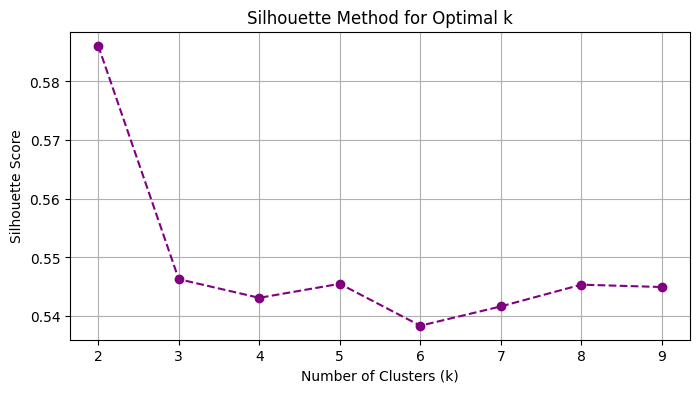

In [5]:
silhouette_scores = []
k_range = range(2, 10)  # 실루엣은 2개 군집부터 계산 가능

print("--- 군집별 실루엣 스코어 확인 ---")
for k in k_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans_test.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)
    print(f"군집 개수 K = {k} | 실루엣 스코어: {score:.4f}")

# 실루엣 스코어 그래프 그리기
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='purple', linestyle='--')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method for Optimal k")
plt.grid(True)
plt.show()